## 1. Setup

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from opa import pattern_u, random_positions, peak_sidelobe

wl, N = 1.55e-6, 64
d_avg, d_min = 2 * wl, 1 * wl          # average gap 2λ, never closer than λ
rng = np.random.default_rng(1)

x_uni = np.arange(N) * d_avg                      # periodic, d = 2λ
x_ape = random_positions(N, d_avg, d_min, rng)    # aperiodic, same average spacing
theta = np.radians(np.linspace(-90, 90, 7201))

We choose d = 2lambda, since this means negligeable crosstalk. It also means a narrow beam from few emitters.

Aperiodic arrays may help us work at larger spacings

## 2. See the two layouts

Both have N emitters

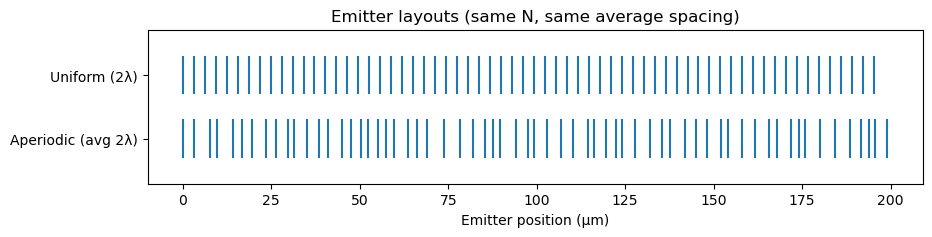

In [9]:
fig, ax = plt.subplots(figsize=(10, 2))
ax.eventplot([x_uni * 1e6, x_ape * 1e6], lineoffsets=[1, 0], linelengths=0.6)
ax.set_yticks([1, 0]); ax.set_yticklabels(["Uniform (2λ)", "Aperiodic (avg 2λ)"])
ax.set_xlabel("Emitter position (µm)"); ax.set_title("Emitter layouts (same N, same average spacing)")
plt.show()

## 3. Beam patterns steered to 30deg

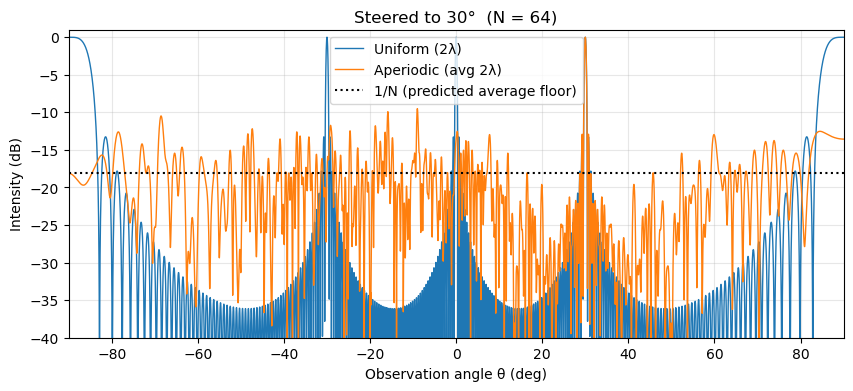

In [19]:
theta0 = 30
u = np.sin(theta) - np.sin(np.radians(theta0))

fig, ax = plt.subplots(figsize=(10, 4))
for name, x in [("Uniform (2λ)", x_uni), ("Aperiodic (avg 2λ)", x_ape)]:
    ax.plot(np.degrees(theta), 10 * np.log10(pattern_u(u, x, wl) + 1e-12), lw=1, label=name)
ax.axhline(10 * np.log10(1 / N), color="k", ls=":", label="1/N (predicted average floor)")
ax.set_ylim(-40, 1); ax.set_xlim(-90, 90)
ax.set_xlabel("Observation angle θ (deg)"); ax.set_ylabel("Intensity (dB)")
ax.set_title(f"Steered to {theta0}°  (N = {N})")
ax.legend(); ax.grid(alpha=0.3); plt.show()

In [11]:
theta0 = 30
s0 = np.sin(np.radians(theta0))
u = np.linspace(-1 - s0, 1 - s0, 40001)                  # exactly the visible window
trap = lambda y, x: np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x))

for name, x in [("Uniform λ/2", np.arange(N) * wl / 2),
                ("Uniform 2λ", x_uni),
                ("Aperiodic avg 2λ", x_ape)]:
    I = pattern_u(u, x, wl)
    main = np.abs(u) < wl / (x[-1] - x[0])                 # main lobe, out to its first null
    print(f"{name:18s}: peak = {I.max():.3f},  fraction of power in main beam = "
          f"{trap(I[main], u[main]) / trap(I, u):.2f}")

Uniform λ/2       : peak = 1.000,  fraction of power in main beam = 0.90
Uniform 2λ        : peak = 1.000,  fraction of power in main beam = 0.23
Aperiodic avg 2λ  : peak = 1.000,  fraction of power in main beam = 0.22


**Why is there 3 full strength lobes for the uniform array?**  - this is what d = 2lambda

Aperiodic and uniform arrays with the same N and width have the same main-beam peak, width and power. Aperiodic spacing doesn’t make the beam brighter. It converts concentrated grating lobes into a weak, even background, which removes ambiguity but not the efficiency loss of sparse spacing.

For a single-beam LIDAR, a uniform 2λ array’s three equal beams are unacceptable: echoes become ambiguous, about three quarters of the light misses the target, and the extra beams use up the eye-safety power budget. It can only be used by limiting the receiver to an “unambiguous” field of view of about ±14.5°. Aperiodic spacing removes the ambiguity across the full field of view instead, although it still doesn’t recover the wasted power.

In [12]:
# Can we investigate width of the main lobe


# 4. Steering maps

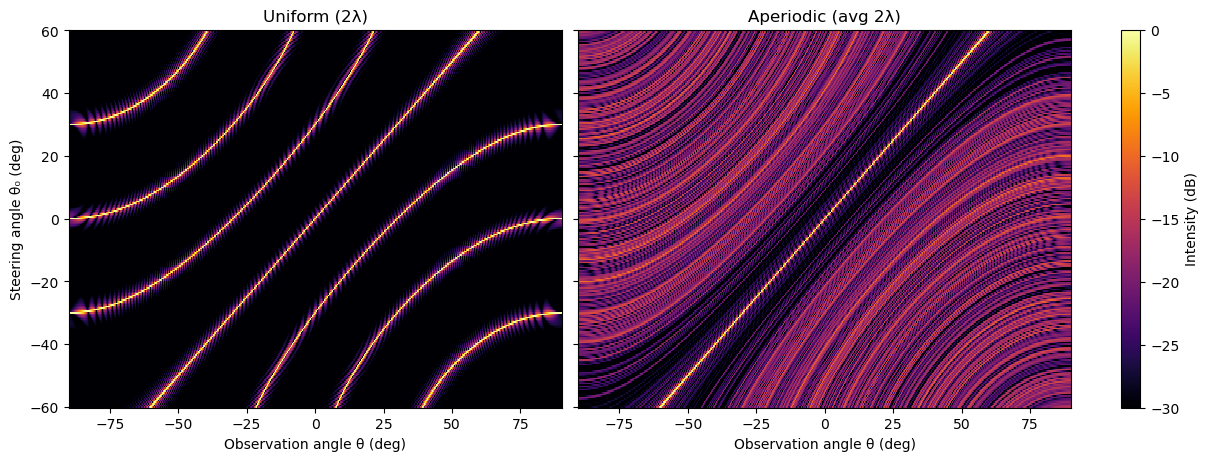

In [13]:
steer = np.linspace(-60, 60, 241)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)
for ax, (name, x) in zip(axes, [("Uniform (2λ)", x_uni), ("Aperiodic (avg 2λ)", x_ape)]):
    rows = [pattern_u(np.sin(theta) - np.sin(np.radians(s)), x, wl) for s in steer]
    im = ax.pcolormesh(np.degrees(theta), steer, 10 * np.log10(np.array(rows) + 1e-12),
                       vmin=-30, vmax=0, shading="auto", cmap="inferno")
    ax.set_title(name); ax.set_xlabel("Observation angle θ (deg)")
axes[0].set_ylabel("Steering angle θ₀ (deg)")
fig.colorbar(im, ax=axes, label="Intensity (dB)")
plt.show()

## 5. Check the floor against theory

In [14]:
I = pattern_u(u, x_ape, wl)
bg = np.abs(u) > 5 * wl / (x_ape[-1] - x_ape[0])
print(f"Average background: {10*np.log10(I[bg].mean()):.1f} dB   (theory 1/N: {10*np.log10(1/N):.1f} dB)")
print(f"Worst sidelobe over ±60° steering: {peak_sidelobe(x_ape, wl):.1f} dB")
print(f"Uniform array, same check:         {peak_sidelobe(x_uni, wl):.1f} dB")

Average background: -19.1 dB   (theory 1/N: -18.1 dB)
Worst sidelobe over ±60° steering: -9.5 dB
Uniform array, same check:         -0.0 dB


In [15]:
# how does the theory (1/N) obtain -18.1 dB

## 6. Optimise the layout

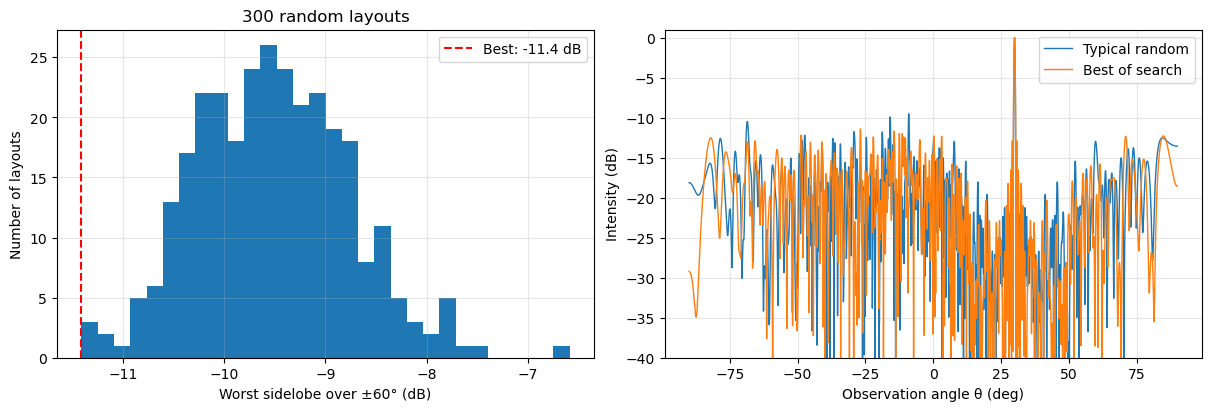

In [20]:
trials = 300
results = []
for _ in range(trials):
    x = random_positions(N, d_avg, d_min, rng)
    results.append((peak_sidelobe(x, wl, fov_deg=60), x))
psl = np.array([r[0] for r in results])
best_psl, x_best = min(results, key=lambda r: r[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(psl, bins=30)
axes[0].axvline(best_psl, color="r", ls="--", label=f"Best: {best_psl:.1f} dB")
axes[0].set_xlabel("Worst sidelobe over ±60° (dB)"); axes[0].set_ylabel("Number of layouts")
axes[0].set_title(f"{trials} random layouts"); axes[0].legend()

u_plot = np.sin(theta) - np.sin(np.radians(theta0))      # matches theta (7201 points)
for name, x in [("Typical random", x_ape), ("Best of search", x_best)]:
    axes[1].plot(np.degrees(theta), 10 * np.log10(pattern_u(u_plot, x, wl) + 1e-12),
                 lw=1, label=name)
axes[1].set_ylim(-40, 1); axes[1].set_xlabel("Observation angle θ (deg)")
axes[1].set_ylabel("Intensity (dB)"); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.show()

In [17]:
print(f"Worst sidelobe across {trials} layouts:")
print(f"  mean   {psl.mean():.1f} dB   (spread ±{psl.std():.1f} dB)")
print(f"  median {np.median(psl):.1f} dB")
print(f"  best   {psl.min():.1f} dB,  worst {psl.max():.1f} dB")

Worst sidelobe across 300 layouts:
  mean   -9.4 dB   (spread ±0.8 dB)
  median -9.5 dB
  best   -11.6 dB,  worst -6.3 dB


We are using random search method

## 7. How much randomness do you need?

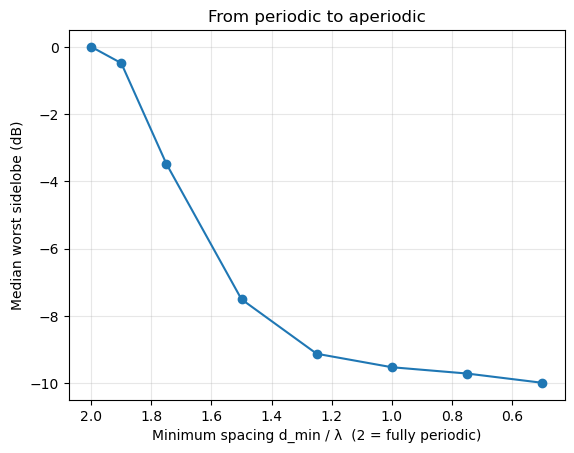

In [18]:
d_mins = np.array([2.0, 1.9, 1.75, 1.5, 1.25, 1.0, 0.75, 0.5]) * wl
median_psl = [np.median([peak_sidelobe(random_positions(N, d_avg, dm, rng), wl) for _ in range(50)])
              for dm in d_mins]
plt.plot(d_mins / wl, median_psl, "o-")
plt.gca().invert_xaxis()
plt.xlabel("Minimum spacing d_min / λ  (2 = fully periodic)"); plt.ylabel("Median worst sidelobe (dB)")
plt.title("From periodic to aperiodic"); plt.grid(alpha=0.3); plt.show()

**Questions/Notes:** 
    
Why are grating lobes a consequence of periodicity?

Where does the grating-lobe power go?

The trade-off: wider spacing means less crosstalk and fewer heaters, but a higher grassy background. That background drops as 1/N, so it improves with more emitters.

Beamwidth is set by the array’s total width, not N. A sparse array gets a narrow beam with few emitters

Real research does exactly this. Komljenovic et al. (2017) optimised emitter positions with particle swarm optimisation. Over a 1 mm aperture, 192 emitters spaced on average more than 3λ apart steered over ±90° with no grating lobes and the strongest sidelobe at least 13.5 dB below the beam. A uniform λ/2 array needs about 1,291 emitters for the same (Optics Express 25, 2017). Your random search is a simple version of their optimisation. Their 13.5 dB with 192 emitters is consistent with your roughly 10 dB with 64, given the 1/N scaling.